# Softmax: one trial, neural response versus age

Edit the parameters below, then **Run All** using your `jax-cuda12` Python environment (JAX, Flax, NumPy, Numba, and Matplotlib). This runs one independently initialized trial with the same protocol as the grid-search runner. The example parameters are starting values, not an optimized configuration.

Each age summarizes many probe patterns **within this one trial**. Age 0 is the response immediately after learning a probe. The plot shows the mean, the 1–99% range, and the steady-state familiarity threshold.

See [the Softmax workflow](notes/softmax.md) for the model and calibration details.


In [33]:
# Model and input parameters
nd = 100
ns = 600
b = 2.6
eta = 8.
beta_select = 4.705
rule = "int"                 # "int" or "nonint"
coeff = None                 # None: independent inputs; >= 1: shared axons
seed = 1234
trial_index = 0              # zero-based repeat index, matching run_softmax.py

# Trial schedule: warm-up, probe recording, washout, steady-state recording.
n_init_steps = 10_000
n_tested_patterns = 1_000
n_steps_phase1 = 3_000        # retained ages = n_steps_phase1 - n_tested_patterns
n_steps_phase2 = 20_000
n_steps_phase3 = 10_000
resample_every = 1_000
test_every_phase3 = 50

# Plot only: changing these does not require another simulation.
max_plot_age = None          # None: show the complete recorded age window
plot_stride = 1              # display every kth age; capacity still uses every age


In [34]:
from pathlib import Path
from time import perf_counter
import sys

import jax
import jax.numpy as jnp
import numpy as np
from matplotlib import pyplot as plt

# Find the repository whether the kernel starts at its root or a subdirectory.
repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "lib" / "neurons.py").is_file()
     and (path / "b_bk_grid_search" / "run_softmax.py").is_file()),
    None,
)
if repo_root is None:
    raise RuntimeError("Start this notebook with the kernel working directory inside the repository.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from lib import driver, input_gen, neurons, utils
from b_bk_grid_search.run_softmax import trial_keys

print("JAX devices:", jax.devices())


JAX devices: [CudaDevice(id=0)]


## Run one trial

Every execution of the next cell resets the weights and runs the full warm-up. With the same seed and trial index it reproduces the same trial; change either for a new realization. Correlated connectivity is fixed throughout a trial and is regenerated from its trial key.

The driver is reused when geometry, rule, input condition, and recording shapes stay fixed. Changing `b`, `eta`, `beta_select`, or the trial seed does not require rebuilding it. The first run compiles the JAX functions.

The phase lengths below follow the existing sweep defaults; adequate equilibration and washout still depend on your parameters.


In [35]:
# Validate before creating large arrays.
counts = dict(
    nd=nd, ns=ns, n_init_steps=n_init_steps, n_tested_patterns=n_tested_patterns,
    n_steps_phase1=n_steps_phase1, n_steps_phase2=n_steps_phase2,
    n_steps_phase3=n_steps_phase3, resample_every=resample_every,
    test_every_phase3=test_every_phase3,
)
if any(not isinstance(value, (int, np.integer)) or value < 1 for value in counts.values()):
    raise ValueError("Geometry, phase lengths, probe counts, and sampling intervals must be positive integers.")
if rule not in ("int", "nonint"):
    raise ValueError('rule must be "int" or "nonint".')
if not np.isfinite([b, eta, beta_select]).all() or eta <= 0 or beta_select < 0:
    raise ValueError("Require finite b, eta > 0, and beta_select >= 0.")
if coeff is not None and (not np.isfinite(coeff) or coeff < 1):
    raise ValueError("coeff must be None or finite and >= 1.")
for name, value in (("seed", seed), ("trial_index", trial_index)):
    if not isinstance(value, (int, np.integer)) or not 0 <= value <= 2**32 - 1:
        raise ValueError(f"{name} must be an integer in [0, 2**32 - 1].")
if any(steps % resample_every for steps in
       (n_init_steps, n_steps_phase1, n_steps_phase2, n_steps_phase3, n_tested_patterns)):
    raise ValueError("Phase lengths and probe count must be multiples of resample_every.")
if n_steps_phase1 <= n_tested_patterns:
    raise ValueError("n_steps_phase1 must exceed n_tested_patterns.")
if resample_every % test_every_phase3:
    raise ValueError("test_every_phase3 must divide resample_every.")

configuration = (nd, ns, rule, coeff, resample_every, n_tested_patterns)
if globals().get("_driver_configuration") != configuration:
    model_class = neurons.Neuron_Softmax_Int if rule == "int" else neurons.Neuron_Softmax_NonInt
    neuron = model_class(neurons.HyperConfigSoftmax(nd=nd, ns=ns))
    if coeff is None:
        generator = input_gen.Normal(nd=nd, ns=ns)
        driver_class = driver.Driver1_bScan
        sample_connectivity = None
    else:
        generator = input_gen.Normal_Corr_across_Dendrites(
            nd=nd, ns=ns, coeff=coeff, key=jax.random.PRNGKey(0),
        )
        driver_class = driver.DriverSoftmax_bScan_Correlated
        sample_connectivity = jax.jit(generator._get_connectivity_idx_mat)
    my_driver = driver_class(
        neuron=neuron, xs_generator=generator, rng=jax.random.PRNGKey(seed),
        resample_every=resample_every, n_tested_patterns=n_tested_patterns,
    )
    _driver_configuration = configuration

simulation_key, connectivity_key = trial_keys(int(seed), int(nd), int(ns), int(trial_index))
dynamic_values = dict(
    b=jnp.asarray(b, dtype=jnp.float32),
    eta=jnp.asarray(eta, dtype=jnp.float32),
    beta_select=jnp.asarray(beta_select, dtype=jnp.float32),
)
if coeff is None:
    hyperD = neurons.HyperDynConfigSoftmax(**dynamic_values)
else:
    hyperD = neurons.HyperDynConfigSoftmax_Correlated(
        **dynamic_values, connectivity=sample_connectivity(connectivity_key),
    )

# Snapshot the parameters so the plot stays correctly labeled if parameters are edited later.
trial_parameters = dict(
    nd=nd, ns=ns, b=b, eta=eta, beta_select=beta_select, rule=rule,
    coeff=coeff, seed=seed, trial_index=trial_index, **{
        name: value for name, value in counts.items() if name not in ("nd", "ns")
    },
)
my_driver.re_init(rng=simulation_key, hyperD=hyperD, initial_state=None)
print("Running warm-up, transient recording, washout, and steady-state recording...", flush=True)
started = perf_counter()
my_driver.run(
    n_init_steps=n_init_steps,
    n_steps_phase1=n_steps_phase1,
    n_steps_phase2=n_steps_phase2,
    n_steps_phase3=n_steps_phase3,
    test_every_phase3=test_every_phase3,
    bs=jnp.asarray([b], dtype=jnp.float32),
)
if not all(np.isfinite(value).all() for value in (
    my_driver.state.w, my_driver.transient_record, my_driver.steady_record, my_driver.upper99_s,
)):
    raise FloatingPointError("The simulation produced nonfinite weights or responses.")

# Keep the original driver arrays for further interactive inspection.
responses = my_driver.transient_record[:, 0, :]  # (age, probe)
steady_responses = my_driver.steady_record[:, 0, :]  # (sampled time, probe)
print(f"Finished in {perf_counter() - started:.1f} s.")
print(f"Transient shape: {responses.shape}; steady-state shape: {steady_responses.shape}")
print(f"Maximum final weight-norm error: {np.max(np.abs(np.linalg.norm(my_driver.state.w, axis=-1) - 1)):.3g}")


Running warm-up, transient recording, washout, and steady-state recording...
Finished in 4.0 s.
Transient shape: (2000, 1000); steady-state shape: (200, 1000)
Maximum final weight-norm error: 1.19e-07


## Response summaries and capacity

The shaded band is variation across probe patterns, **not a confidence interval across trials**. The lower and upper tails use the same order-statistic convention as the capacity estimator. The horizontal threshold pools the steady-state samples across times and probes and adds the estimator's small epsilon.

Capacity is the mean of the ages immediately preceding downward crossings of the familiar lower tail below the threshold. A returned value of zero can also mean no crossing was observed; the diagnostic below distinguishes these cases.


In [36]:
ages = np.arange(responses.shape[0])
probe_count = responses.shape[1]
lower_index = max(0, int(np.ceil(0.01 * probe_count)) - 1)
upper_index = max(0, int(np.ceil(0.99 * probe_count)) - 1)
partitioned = np.partition(responses, (lower_index, upper_index), axis=1)
response_mean = responses.mean(axis=1)
response_lower = partitioned[:, lower_index].copy()
response_upper = partitioned[:, upper_index].copy()
del partitioned

steady_mean = float(steady_responses.mean())
steady_threshold = float(my_driver.upper99_s[0])
capacity = float(utils.capacity_numba(
    my_driver.transient_record, my_driver.steady_record, my_driver.upper99_s,
)[0])

margin = response_lower - steady_threshold
crossing_ages = np.flatnonzero((margin[:-1] >= 0) & (margin[1:] < 0))
if crossing_ages.size:
    capacity_status = f"{crossing_ages.size} downward crossing(s); capacity = {capacity:.2f} patterns."
elif np.all(margin >= 0):
    capacity_status = "No crossing: the lower tail remains above threshold; extend the age window."
elif np.all(margin < 0):
    capacity_status = "No crossing: the lower tail is already below threshold at every recorded age."
else:
    capacity_status = "No downward crossing: the lower tail crosses upward only in this age window."

print(capacity_status)
print(f"Steady-state mean: {steady_mean:.6g}; familiarity threshold: {steady_threshold:.6g}")


5 downward crossing(s); capacity = 121.20 patterns.
Steady-state mean: 0.148639; familiarity threshold: 1.31629


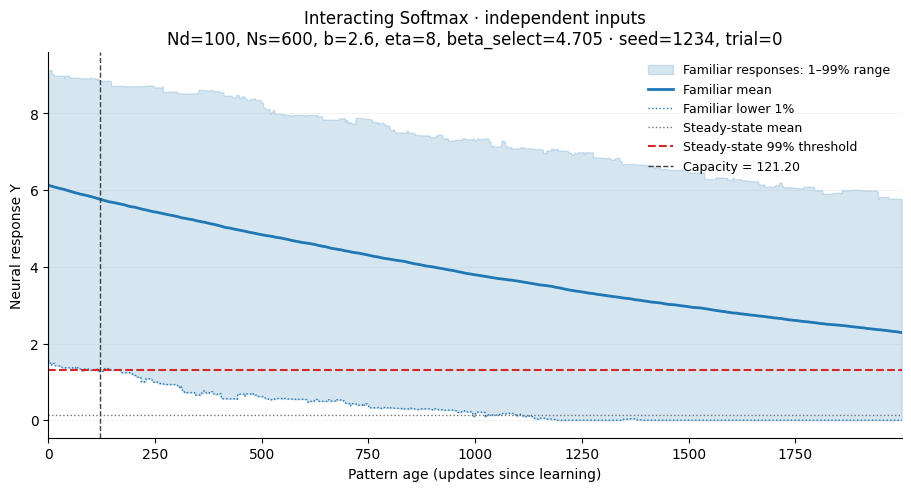

In [37]:
if not isinstance(plot_stride, (int, np.integer)) or plot_stride < 1:
    raise ValueError("plot_stride must be a positive integer.")
if max_plot_age is not None and (not np.isfinite(max_plot_age) or max_plot_age < 0):
    raise ValueError("max_plot_age must be None or finite and nonnegative.")

visible = ages if max_plot_age is None else ages[ages <= max_plot_age]
shown = visible[::plot_stride]
# Always include the final visible age, even when downsampling for display.
shown = np.unique(np.append(shown, visible[-1]))

fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
ax.fill_between(
    ages[shown], response_lower[shown], response_upper[shown],
    color="tab:blue", alpha=0.18, label="Familiar responses: 1–99% range",
)
ax.plot(ages[shown], response_mean[shown], color="tab:blue", linewidth=2, label="Familiar mean")
ax.plot(ages[shown], response_lower[shown], color="tab:blue", linewidth=1,
        linestyle=":", label="Familiar lower 1%")
ax.axhline(steady_mean, color="0.45", linewidth=1, linestyle=":", label="Steady-state mean")
ax.axhline(steady_threshold, color="tab:red", linewidth=1.5, linestyle="--",
           label="Steady-state 99% threshold")
if crossing_ages.size and capacity <= visible[-1]:
    ax.axvline(capacity, color="0.25", linestyle="--", linewidth=1,
               label=f"Capacity = {capacity:.2f}")

p = trial_parameters
rule_label = "Interacting" if p["rule"] == "int" else "Non-interacting"
input_label = "independent inputs" if p["coeff"] is None else f"shared axons, c={p['coeff']:g}"
ax.set_title(
    f"{rule_label} Softmax · {input_label}\n"
    f"Nd={p['nd']}, Ns={p['ns']}, b={p['b']:g}, eta={p['eta']:g}, "
    f"beta_select={p['beta_select']:g} · seed={p['seed']}, trial={p['trial_index']}"
)
ax.set_xlabel("Pattern age (updates since learning)")
ax.set_ylabel("Neural response Y")
ax.set_xlim(0, max(1, int(visible[-1])))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.legend(frameon=False, fontsize=9)
plt.show()


You can rerun the plot cell without running the simulation again. Inspect `responses`, `steady_responses`, `my_driver.state.w`, `crossing_ages`, and `trial_parameters` for further analysis.

To save the figure, uncomment the final cell. No simulation results are appended to the grid-search CSVs.


In [17]:
# output_path = repo_root / "tmp_figures" / "softmax_trial_response.png"
# output_path.parent.mkdir(parents=True, exist_ok=True)
# fig.savefig(output_path, dpi=200, bbox_inches="tight")
